<a href="https://colab.research.google.com/github/Quynhanh746/Python-2026-L1/blob/main/2410127_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Practice 3
#Part 1

In [26]:
import matplotlib.pyplot as plt
import numpy as np


def verif_sdd(A):
    """Kiểm tra ma trận A có chéo trội nghiêm ngặt (SDD) hay không."""
    n = A.shape[0]
    for i in range(n):
        diag = abs(A[i, i])
        off_diag = sum(abs(A[i, j]) for j in range(n) if j != i)
        if diag <= off_diag:
            return False
    return True


def solve_jacobi(A, b, x0=None, tol=1e-6, max_iter=50):
    n = len(b)
    if x0 is None:
        x = np.zeros(n, dtype=float)
    else:
        x = x0.copy().astype(float)

    x_nxt = np.zeros_like(x)
    residual_track = []

    for k in range(max_iter):
        r = b - A @ x
        res_norm = np.max(np.abs(r))
        residual_track.append(res_norm)

        if res_norm < tol:
            return x, k, residual_track

        for i in range(n):
            s = sum(A[i, j] * x[j] for j in range(n) if j != i)
            x_nxt[i] = (b[i] - s) / A[i, i]

        x = x_nxt.copy()

    raise TimeoutError(f"Convergence failed within max_iter={max_iter}!")


# --- Chạy kiểm thử cho Application ---
A = np.array([[5.0, -1.0, 1.0], [2.0, 8.0, -1.0], [-1.0, 1.0, 4.0]])
b = np.array([10.0, 11.0, 11.0])

# 1. SDD Check
is_sdd = verif_sdd(A)
print(f"Ma trận A là SDD?: {is_sdd}")

# 3. Solve Jacobi
x_jac, k_jac, res_jac = solve_jacobi(A, b, tol=1e-6)
print(f"Nghiệm Jacobi: {x_jac}")
print(f"Số vòng lặp (k_jacobi): {k_jac}")

Ma trận A là SDD?: True
Nghiệm Jacobi: [1.69230763 1.30769235 2.84615386]
Số vòng lặp (k_jacobi): 16


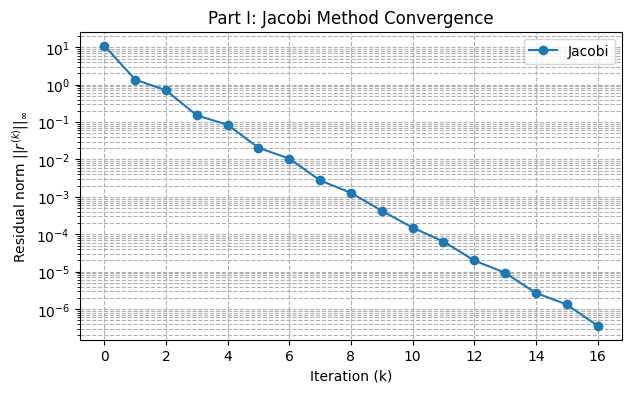

In [27]:
plt.figure(figsize=(7, 4))
plt.semilogy(range(len(res_jac)), res_jac, "o-", label="Jacobi")
plt.xlabel("Iteration (k)")
plt.ylabel(r"Residual norm $||r^{(k)}||_{\infty}$")
plt.title("Part I: Jacobi Method Convergence")
plt.grid(True, which="both", linestyle="--")
plt.legend()
plt.show()

#part 2

In [20]:
def solve_gauss_seidel(A, b, x0=None, tol=1e-6, max_iter=100):
    n = len(b)
    if x0 is None:
        x = np.zeros(n, dtype=float)
    else:
        x = x0.copy().astype(float)

    residual_track = []

    for k in range(max_iter):
        r = b - A @ x
        res_norm = np.max(np.abs(r))
        residual_track.append(res_norm)

        if res_norm < tol:
            return x, k, residual_track

        for i in range(n):
            s1 = sum(A[i, j] * x[j] for j in range(i))
            s2 = sum(A[i, j] * x[j] for j in range(i + 1, n))
            x[i] = (b[i] - s1 - s2) / A[i, i]

    raise TimeoutError(f"Convergence failed within max_iter={max_iter}!")


# Chạy thử nghiệm
x_gs, k_gs, res_gs = solve_gauss_seidel(A, b, tol=1e-6)
print(f"Nghiệm Gauss-Seidel: {x_gs}")
print(f"Số vòng lặp (k_gs): {k_gs}")

#part 3

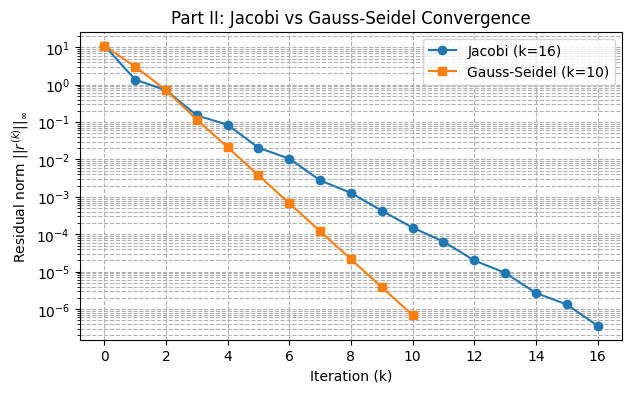

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Khai báo ma trận A và b từ Bài tập 1 & 2
A = np.array([[5.0, -1.0, 1.0], [2.0, 8.0, -1.0], [-1.0, 1.0, 4.0]])
b = np.array([10.0, 11.0, 11.0])


# 2. Định nghĩa các hàm giải hệ phương trình
def solve_jacobi(A, b, x0=None, tol=1e-6, max_iter=50):
    n = len(b)
    x = np.zeros(n, dtype=float) if x0 is None else x0.copy().astype(float)
    x_nxt = np.zeros_like(x)
    residual_track = []

    for k in range(max_iter):
        r = b - A @ x
        res_norm = np.max(np.abs(r))
        residual_track.append(res_norm)
        if res_norm < tol:
            return x, k, residual_track
        for i in range(n):
            s = sum(A[i, j] * x[j] for j in range(n) if j != i)
            x_nxt[i] = (b[i] - s) / A[i, i]
        x = x_nxt.copy()
    raise TimeoutError(f"Convergence failed within max_iter={max_iter}!")


def solve_gauss_seidel(A, b, x0=None, tol=1e-6, max_iter=100):
    n = len(b)
    x = np.zeros(n, dtype=float) if x0 is None else x0.copy().astype(float)
    residual_track = []

    for k in range(max_iter):
        r = b - A @ x
        res_norm = np.max(np.abs(r))
        residual_track.append(res_norm)
        if res_norm < tol:
            return x, k, residual_track
        for i in range(n):
            s1 = sum(A[i, j] * x[j] for j in range(i))
            s2 = sum(A[i, j] * x[j] for j in range(i + 1, n))
            x[i] = (b[i] - s1 - s2) / A[i, i]
    raise TimeoutError(f"Convergence failed within max_iter={max_iter}!")


# 3. Chạy phương pháp để tạo biến res_jac, k_jac, res_gs, k_gs
x_jac, k_jac, res_jac = solve_jacobi(A, b, tol=1e-6)
x_gs, k_gs, res_gs = solve_gauss_seidel(A, b, tol=1e-6)

# 4. Vẽ đồ thị
plt.figure(figsize=(7, 4))
plt.semilogy(range(len(res_jac)), res_jac, "o-", label=f"Jacobi (k={k_jac})")
plt.semilogy(range(len(res_gs)), res_gs, "s-", label=f"Gauss-Seidel (k={k_gs})")
plt.xlabel("Iteration (k)")
plt.ylabel(r"Residual norm $||r^{(k)}||_{\infty}$")
plt.title("Part II: Jacobi vs Gauss-Seidel Convergence")
plt.grid(True, which="both", linestyle="--")
plt.legend()
plt.show()

#part 4

In [22]:
def fit_vandermonde(x, y):
    V = np.vander(x, increasing=True)
    c = np.linalg.solve(V, y)
    return c

def calc_horner(x_eval, c):
    n = len(c) - 1
    p = c[n] * np.ones_like(x_eval, dtype=float)
    for i in range(n - 1, -1, -1):
        p = c[i] + x_eval * p
    return p

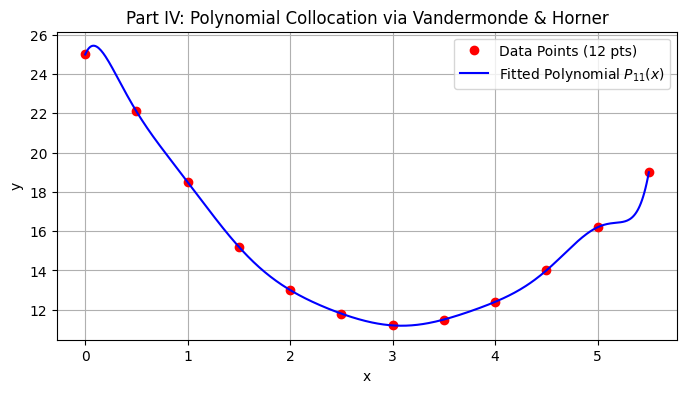

In [31]:
import matplotlib.pyplot as plt
import numpy as np


# 1. Định nghĩa hàm tìm hệ số Vandermonde và tính giá trị Horner
def fit_vandermonde(x, y):
    V = np.vander(x, increasing=True)
    return np.linalg.solve(V, y)


def calc_horner(x_eval, c):
    n = len(c) - 1
    p = c[n] * np.ones_like(x_eval, dtype=float)
    for i in range(n - 1, -1, -1):
        p = p * x_eval + c[i]
    return p


# 2. Khai báo dữ liệu 12 điểm (Part IV)
x_data = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5])
y_data = np.array(
    [25.0, 22.1, 18.5, 15.2, 13.0, 11.8, 11.2, 11.5, 12.4, 14.0, 16.2, 19.0]
)

# 3. Tính toán đa thức nội suy P_11(x)
c_poly = fit_vandermonde(x_data, y_data)
x_fine = np.linspace(0, 5.5, 500)
y_fine = calc_horner(x_fine, c_poly)

# 4. Vẽ đồ thị
plt.figure(figsize=(8, 4))
plt.plot(x_data, y_data, "ro", label="Data Points (12 pts)")
plt.plot(x_fine, y_fine, "b-", label=r"Fitted Polynomial $P_{11}(x)$")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Part IV: Polynomial Collocation via Vandermonde & Horner")
plt.legend()
plt.grid(True)
plt.show()

#part 5


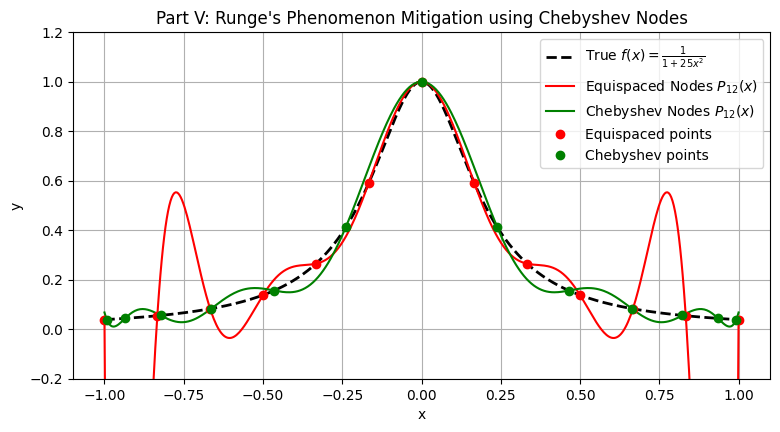

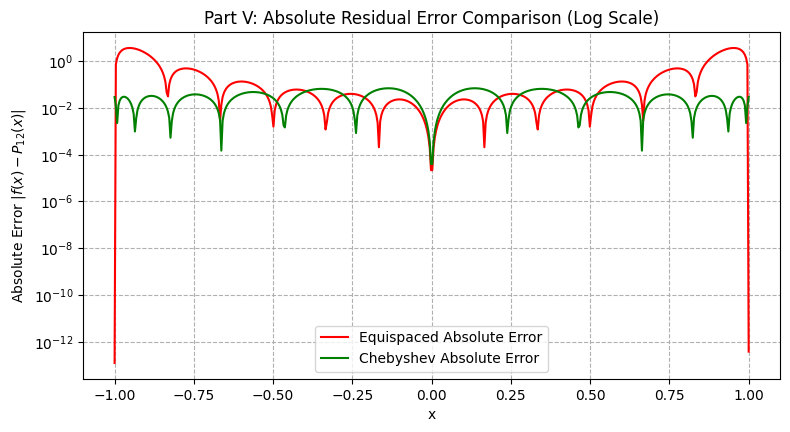

In [33]:
import matplotlib.pyplot as plt
import numpy as np


# 1. Các hàm hỗ trợ
def fit_vandermonde(x, y):
    V = np.vander(x, increasing=True)
    return np.linalg.solve(V, y)


def calc_horner(x_eval, c):
    n = len(c) - 1
    p = c[n] * np.ones_like(x_eval, dtype=float)
    for i in range(n - 1, -1, -1):
        p = p * x_eval + c[i]
    return p


def chebyshev_nodes(a, b, n):
    i = np.arange(n + 1)
    return (a + b) / 2 + (b - a) / 2 * np.cos((2 * i + 1) / (2 * n + 2) * np.pi)


def f_runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)


# 2. Khởi tạo dữ liệu cho bậc n = 12
n = 12

# Nút cách đều
x_eq = np.linspace(-1, 1, n + 1)
y_eq = f_runge(x_eq)
c_eq = fit_vandermonde(x_eq, y_eq)

# Nút Chebyshev
x_cheb = chebyshev_nodes(-1, 1, n)
y_cheb = f_runge(x_cheb)
c_cheb = fit_vandermonde(x_cheb, y_cheb)

# Lưới đánh giá mịn
x_fine = np.linspace(-1, 1, 500)
y_true = f_runge(x_fine)
y_poly_eq = calc_horner(x_fine, c_eq)
y_poly_cheb = calc_horner(x_fine, c_cheb)

# 3. Biểu đồ 1: So sánh đường cong nội suy
plt.figure(figsize=(9, 4.5))
plt.plot(x_fine, y_true, "k--", label=r"True $f(x) = \frac{1}{1+25x^2}$", lw=2)
plt.plot(x_fine, y_poly_eq, "r-", label=r"Equispaced Nodes $P_{12}(x)$")
plt.plot(x_fine, y_poly_cheb, "g-", label=r"Chebyshev Nodes $P_{12}(x)$")
plt.plot(x_eq, y_eq, "ro", label="Equispaced points")
plt.plot(x_cheb, y_cheb, "go", label="Chebyshev points")
plt.ylim(-0.2, 1.2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Part V: Runge's Phenomenon Mitigation using Chebyshev Nodes")
plt.legend()
plt.grid(True)
plt.show()

# 4. Biểu đồ 2: Biểu đồ Log Sai số tuyệt đối
plt.figure(figsize=(9, 4.5))
plt.semilogy(
    x_fine,
    np.abs(y_true - y_poly_eq) + 1e-16,
    "r-",
    label="Equispaced Absolute Error",
)
plt.semilogy(
    x_fine,
    np.abs(y_true - y_poly_cheb) + 1e-16,
    "g-",
    label="Chebyshev Absolute Error",
)
plt.xlabel("x")
plt.ylabel(r"Absolute Error $|f(x) - P_{12}(x)|$")
plt.title("Part V: Absolute Residual Error Comparison (Log Scale)")
plt.legend()
plt.grid(True, which="both", linestyle="--")
plt.show()

#part 6

Cubic Spline elevation S(3.5)   : 379.4249
Cubic Spline slope S'(3.5)       : 116.1653
Global Poly elevation P14(3.5)  : 382.0850


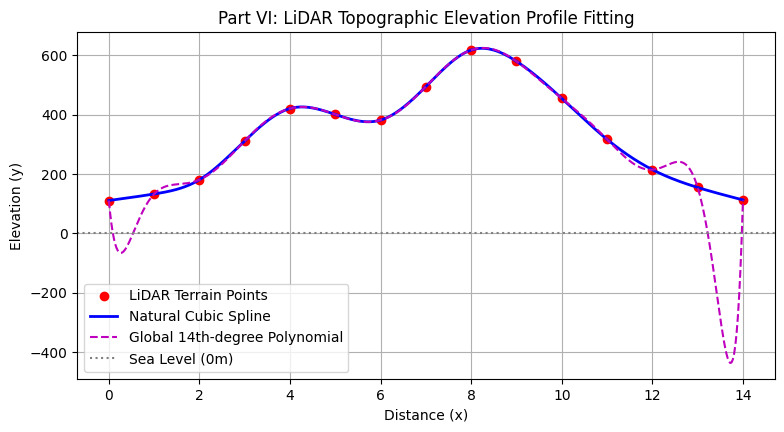

In [34]:
from scipy.interpolate import CubicSpline

x_knots = np.linspace(0, 14, 15)
y_knots = np.array(
    [111, 133, 181, 312, 421, 401, 382, 495, 618, 580, 455, 317, 215, 155, 113]
)

# 1. Natural Cubic Spline
cs = CubicSpline(x_knots, y_knots, bc_type="natural")

# 2. Global Polynomial bậc 14
c_global = fit_vandermonde(x_knots, y_knots)

# 3. Đánh giá trên x_fine
x_fine = np.linspace(0, 14, 500)
y_spline = cs(x_fine)
y_global = calc_horner(x_fine, c_global)

# Giá trị tại x = 3.5 (Checkpoint #6)
elev_spline_35 = cs(3.5)
slope_spline_35 = cs(3.5, 1)  # Đạo hàm cấp 1
elev_global_35 = calc_horner(3.5, c_global)

print(f"Cubic Spline elevation S(3.5)   : {elev_spline_35:.4f}")
print(f"Cubic Spline slope S'(3.5)       : {slope_spline_35:.4f}")
print(f"Global Poly elevation P14(3.5)  : {elev_global_35:.4f}")
plt.figure(figsize=(9, 4.5))
plt.plot(x_knots, y_knots, "ro", markersize=6, label="LiDAR Terrain Points")
plt.plot(x_fine, y_spline, "b-", linewidth=2, label="Natural Cubic Spline")
plt.plot(
    x_fine,
    y_global,
    "m--",
    linewidth=1.5,
    label="Global 14th-degree Polynomial",
)
plt.axhline(0, color="gray", linestyle=":", label="Sea Level (0m)")
plt.xlabel("Distance (x)")
plt.ylabel("Elevation (y)")
plt.title("Part VI: LiDAR Topographic Elevation Profile Fitting")
plt.legend()
plt.grid(True)
plt.show()